In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

In [2]:
clustering_approach = pd.read_csv('../data/processed/baseline_sequence_clusters.csv', index_col='tcr_id')
alphafold_approach = pd.read_csv('../data/processed/alphafold_predictions.csv', index_col='tcr_id')

In [3]:
ensemble = clustering_approach.merge(
    alphafold_approach, how='inner', left_index=True, right_index=True, suffixes=('_cluster', '_af3')
)

In [4]:
ensemble['prediction_mean'] = (ensemble['prediction_cluster'] + ensemble['prediction_af3']) / 2

In [5]:
public_labels = pd.read_csv('../data/external/ttd_gil_ylq_nlv_glc_01-10-2026_TCRvdb.csv', index_col='tcr_id')

In [6]:
ensemble_public = ensemble.merge(public_labels.query('ambiguous == 0'), how='inner', left_index=True, right_index=True)

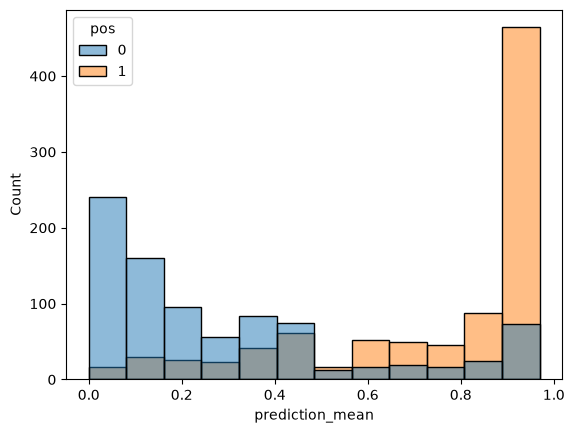

In [7]:
sns.histplot(ensemble_public, x='prediction_mean', hue='pos', multiple='layer')
plt.show()

In [8]:
print('Ensemble Score:', roc_auc_score(ensemble_public['pos'], ensemble_public['prediction_mean']))

Ensemble Score: 0.8591806129650166


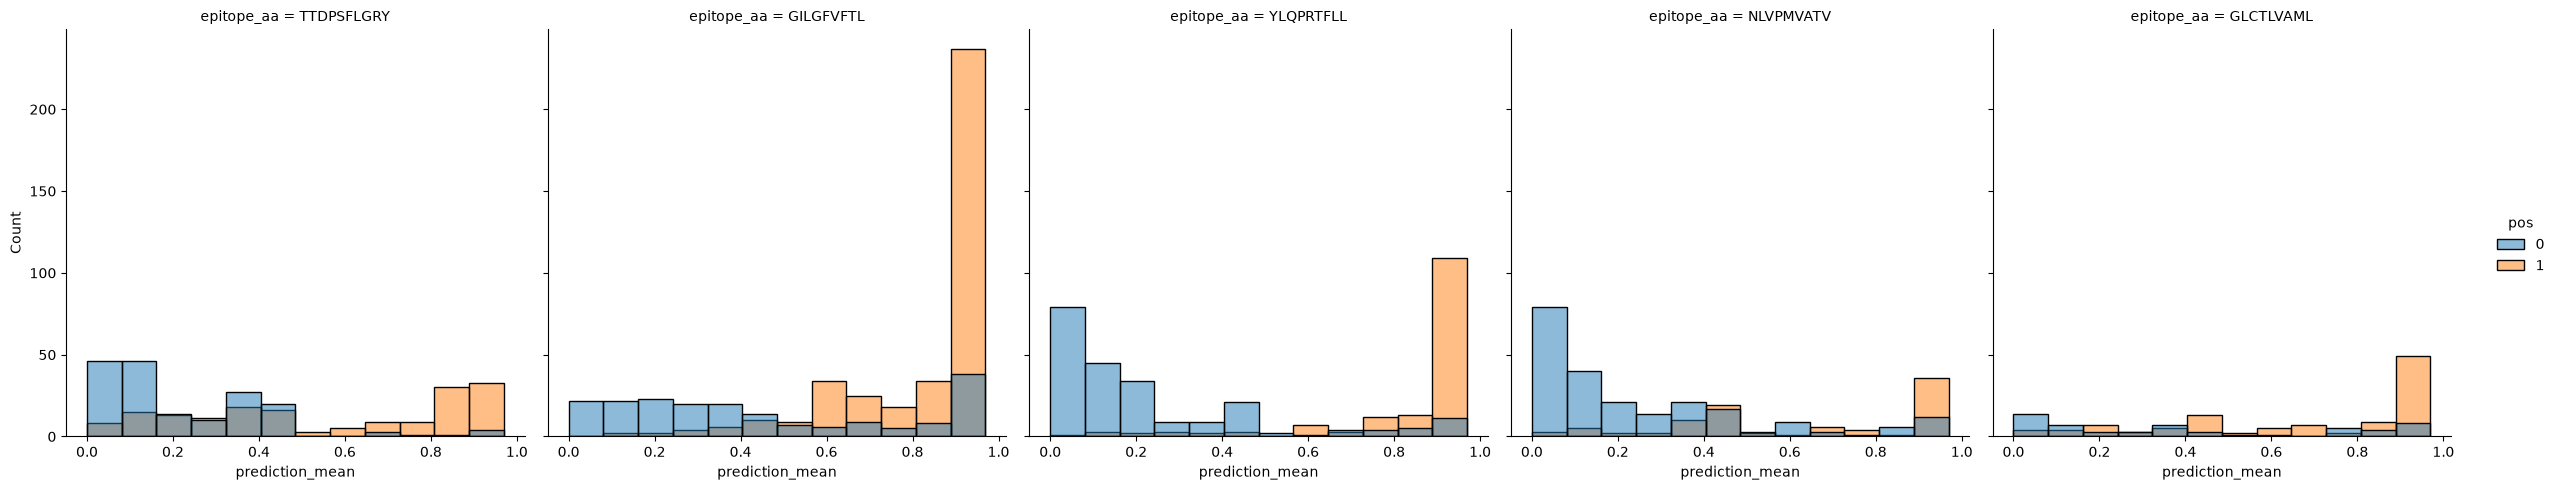

In [9]:
sns.displot(ensemble_public, x='prediction_mean', col='epitope_aa', hue='pos')
plt.show()

In [10]:
per_peptide_performance = (
    ensemble_public.groupby('epitope_aa')
    .apply(lambda group: roc_auc_score(group['pos'], group['prediction_mean']), include_groups=False)
    .sort_values(ascending=False)
)

print(per_peptide_performance, end='\n\n')
print('Macro-averaged ROC-AUC for combined method:', per_peptide_performance.mean())

epitope_aa
YLQPRTFLL     0.935070
GILGFVFTL     0.834984
NLVPMVATV     0.831275
TTDPSFLGRY    0.802428
GLCTLVAML     0.753896
dtype: float64

Macro-averaged ROC-AUC for combined method: 0.831530635356447


In [11]:
(
    ensemble[['prediction_mean']]
    .rename({'prediction_mean': 'prediction'}, axis='columns')
    .to_csv('../data/processed/ensemble_predictions.csv')
)